In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from hidro_tools import modelo_tanques
from hidro_tools import funcion_objetivo
from pysheds.grid import Grid
from pysheds.view import Raster, ViewFinder
from pathlib import Path
import xarray as xr
import matplotlib.colors as colors
import rioxarray 
import glob
import re
import random
import os

In [2]:
# Lectura de datos
df = pd.read_csv(
    '0022057010-Q_MEDIA_D.csv',
    index_col=0,
    parse_dates=True,
    usecols=[0,1]
)
df = df.resample('D').mean()

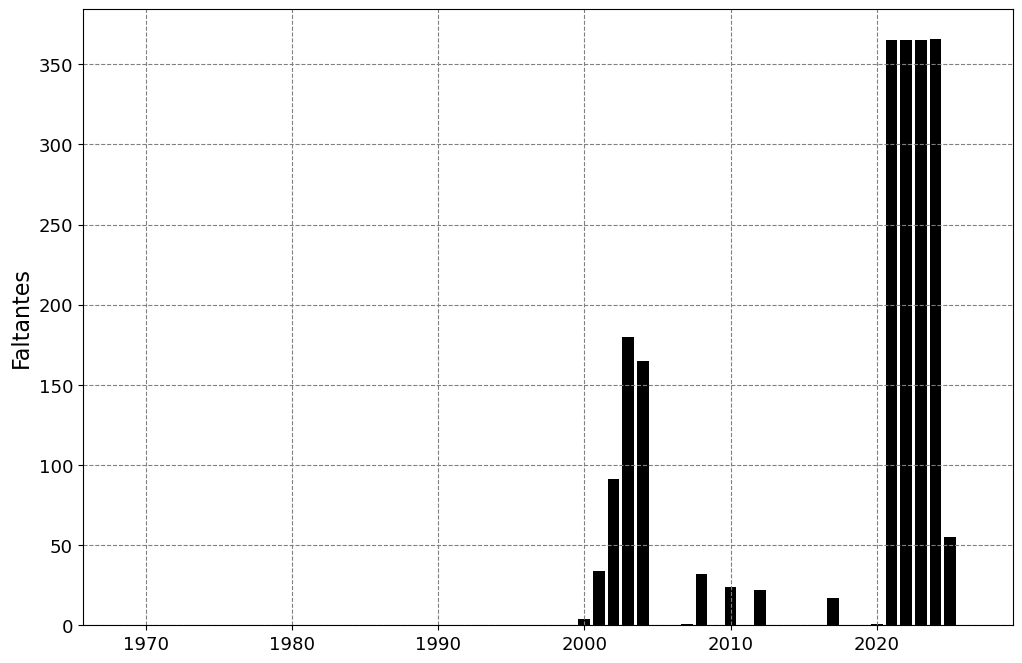

In [3]:
faltantes = df.isna().groupby(df.index.year).sum()
# ploteo de los faltantes
x = faltantes.index
y = faltantes.iloc[:,0]
plt.figure(figsize=(12,8))
plt.bar(x=x,height=y,color='black')
plt.ylabel('Faltantes',fontsize=16)
plt.yticks(size=13)
plt.xticks(size=13)
plt.grid(linestyle='--',color='grey')

## Delimitacion cuenca Piedra de Cobre

In [29]:
crs = 9377
gdf = gpd.read_file('CNE_actualizado')
gdf = gdf.to_crs(crs)
mask = gdf['Codigo'] == '22057010'
est_piedra_cobre = gdf[mask].copy()
lon = est_piedra_cobre.get_coordinates().iloc[0,0]
lat = est_piedra_cobre.get_coordinates().iloc[0,1]

In [53]:
est_piedra_cobre.to_file('estacion_punta_cobre')

In [30]:
# Set plotting style
plt.style.use("bmh")

In [68]:
path = 'dem_region_v2.tif'
dem = xr.open_dataset(path,engine='rasterio')
dem = dem.rename({"band_data": "elevation"})
dem = dem['elevation'][0, :, :]
dem = dem.where(dem != 0)
dem = dem.rio.write_crs('EPSG:32618')          # CRS original (solo etiqueta)
dem = dem.rio.write_nodata(float('nan'), encoded=False)

dem_9377 = dem.rio.reproject(
    'EPSG:9377',
    resolution=30,   # ajusta a tu resolución original (m); evita celdas no cuadradas o remuestreo no deseado
)

In [136]:
data = dem_9377.data
affine = dem_9377.rio.transform()
crs = dem_9377.rio.crs
# Keep same data type as DEM values for nodata
nodata = data.dtype.type(np.nan)

In [137]:
viewfinder = ViewFinder(affine=affine, shape=data.shape, crs=crs, nodata=nodata)
dem = Raster(data, viewfinder=viewfinder)

In [138]:
# Create grid
grid = Grid.from_raster(dem)

In [139]:
# Detect number of pits in DEM
pits = grid.detect_pits(dem)
npits = np.count_nonzero(pits)

# Check number of pits
print(f"Number of pits found: {npits}")

Number of pits found: 71250


In [140]:
# Fill pits and check they have been filled
pit_filled_dem = grid.fill_pits(dem)
pits = grid.detect_pits(pit_filled_dem)
assert not pits.any()

In [141]:
depressions = grid.detect_depressions(pit_filled_dem)

In [142]:
# Fill depressions - Slow, takes 5-10 minutes...
flooded_dem = grid.fill_depressions(pit_filled_dem)
depressions = grid.detect_depressions(flooded_dem)
assert not depressions.any()

In [143]:
inflated_dem = grid.resolve_flats(flooded_dem, max_iter=1e9, eps=1e-12)

In [144]:
# Compute flow direction based on corrected DEM (D8)
fdir = grid.flowdir(inflated_dem)

# Compute flow accumulation based on computed flow direction
acc = grid.accumulation(fdir)

In [145]:
outlet = (float(lon), float(lat))
# Snap outlet point to nearby cell with high flow accumulation
x_snap, y_snap = grid.snap_to_mask(acc > 1000, outlet)

# Delineate the watershed
catch = grid.catchment(x=x_snap, y=y_snap, fdir=fdir,xytype="coordinate")

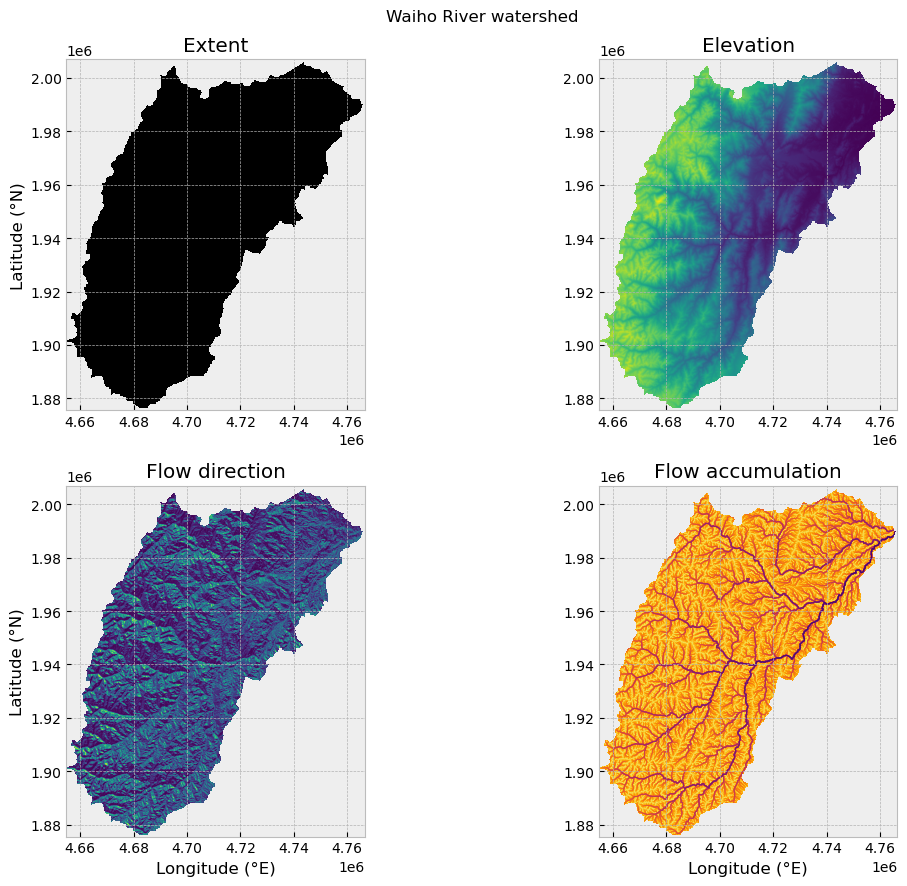

In [146]:
# Clip and set view extents
grid.clip_to(catch)
catch_view = grid.view(catch, nodata=np.nan)
dem_view = grid.view(dem, nodata=np.nan)
fdir_view = grid.view(fdir, nodata=np.nan)
acc_view = grid.view(acc, nodata=np.nan)

# Create figure and plot axes
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.patch.set_alpha(0)

# Plot watershed extent
im = axes[0, 0].imshow(catch_view, extent=grid.extent, zorder=1, cmap="Greys_r")
axes[0, 0].set_title("Extent")
axes[0, 0].set_ylabel("Latitude (°N)")

# Plot watershed elevations
im = axes[0, 1].imshow(dem_view, extent=grid.extent, zorder=1, cmap="viridis")
axes[0, 1].set_title("Elevation")

# Plot watershed flow directions
im = axes[1, 0].imshow(fdir_view, extent=grid.extent, zorder=1, cmap="viridis")
axes[1, 0].set_title("Flow direction")
axes[1, 0].set_xlabel("Longitude (°E)")
axes[1, 0].set_ylabel("Latitude (°N)")

# Plot watershed flow accumulation
im = axes[1, 1].imshow(
    acc_view,
    extent=grid.extent,
    zorder=1,
    cmap="inferno_r",
    norm=colors.LogNorm(1, acc.max()),
)
axes[1, 1].set_title("Flow accumulation")
axes[1, 1].set_xlabel("Longitude (°E)")

# Add a figure title
plt.suptitle("Waiho River watershed")
plt.tight_layout()

In [147]:
# catch = grid.catchment(x=x_out, y=y_out, fdir=fdir, xytype='coordinate')

# 1. Recortar el grid a la extensión de la cuenca
grid.clip_to(catch)

# 2. Vista de la máscara de la cuenca (ya recortada)
catch_view = grid.view(catch, nodata=0)

# 3. Guardar como GeoTIFF (la máscara es booleana, conviene pasarla a uint8)
grid.to_raster(
    catch_view.astype('uint8'),
    'cuenca_saldana_mask.tif',
    target_view=grid.viewfinder,
    blockxsize=256,
    blockysize=256,
    nodata=0,
)

## Modelo Hidrológico 
Se ajustan modelos de lluvia escorrentía Velez et al (2000) y GR4J.
Insumos:
- Precipitación CHIRPS 1981 - 2026 promediada zonalmente a nivel de cuenca
- ETP: Inicialmente Cenicafé, para ajuste inicial, luego se pueden utilizar otras entradas como Turc, Hargreaves o Thornwaite

### Precipitación IDEAM

In [18]:
# Se recortan los datos del CNE con la cuenca de Saldaña
cuenca_saldana = gpd.read_file('cuenca_saldana')
cne = gpd.read_file('CNE_actualizado')
cne = cne.to_crs(cuenca_saldana.crs)
# Clipeo de los datos
cne_clipped = cne.clip(cuenca_saldana)
cne_clipped.loc[:,'Fecha_inst'] = pd.to_datetime(cne_clipped['Fecha_inst']) 

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_5276\1005381965.py:7: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cne_clipped.loc[:,'Fecha_inst'] = pd.to_datetime(cne_clipped['Fecha_inst'])


In [19]:
categorias = ['Pluviométrica','Pluviográfica']
mask = (cne_clipped['Categoria'].isin(categorias)) & \
    (cne_clipped['Estado'] == 'Activa') & \
    (cne_clipped['Fecha_inst'] <= pd.to_datetime('2000-01-01'))
    
estaciones_pptn = cne_clipped[mask] 
estaciones_pptn.set_index('Codigo',drop=True,inplace=True)

In [21]:
# Estacion IDEAM
path = 'pptn_colombia'
files = os.listdir(path)

dict_files = {
    'files_path' : [os.path.join(path,file) for file in files],
    'cods' : [file.split('@')[1].split('.')[0] for file in files]
}
df_files = pd.DataFrame.from_dict(dict_files)
# Actualizacion
df_files.set_index('cods',drop=True,inplace=True)
# join de los dataframes
estaciones_pptn['files_path'] = df_files['files_path'].copy()

c:\Users\USUARIO\miniconda3\envs\cds\Lib\site-packages\geopandas\geodataframe.py:1528: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


In [24]:
# Retener estaciones
columnas = ['Nombre','Fecha_inst','X','Y','files_path','geometry']
estaciones_pptn = estaciones_pptn[columnas]

In [29]:
# Fechas de las estaciones
fecha_minima = estaciones_pptn['Fecha_inst'].min()
fecha_superior = '2025-12-31'
date_range = pd.date_range(
    fecha_minima,
    fecha_superior,
    freq='D'
)

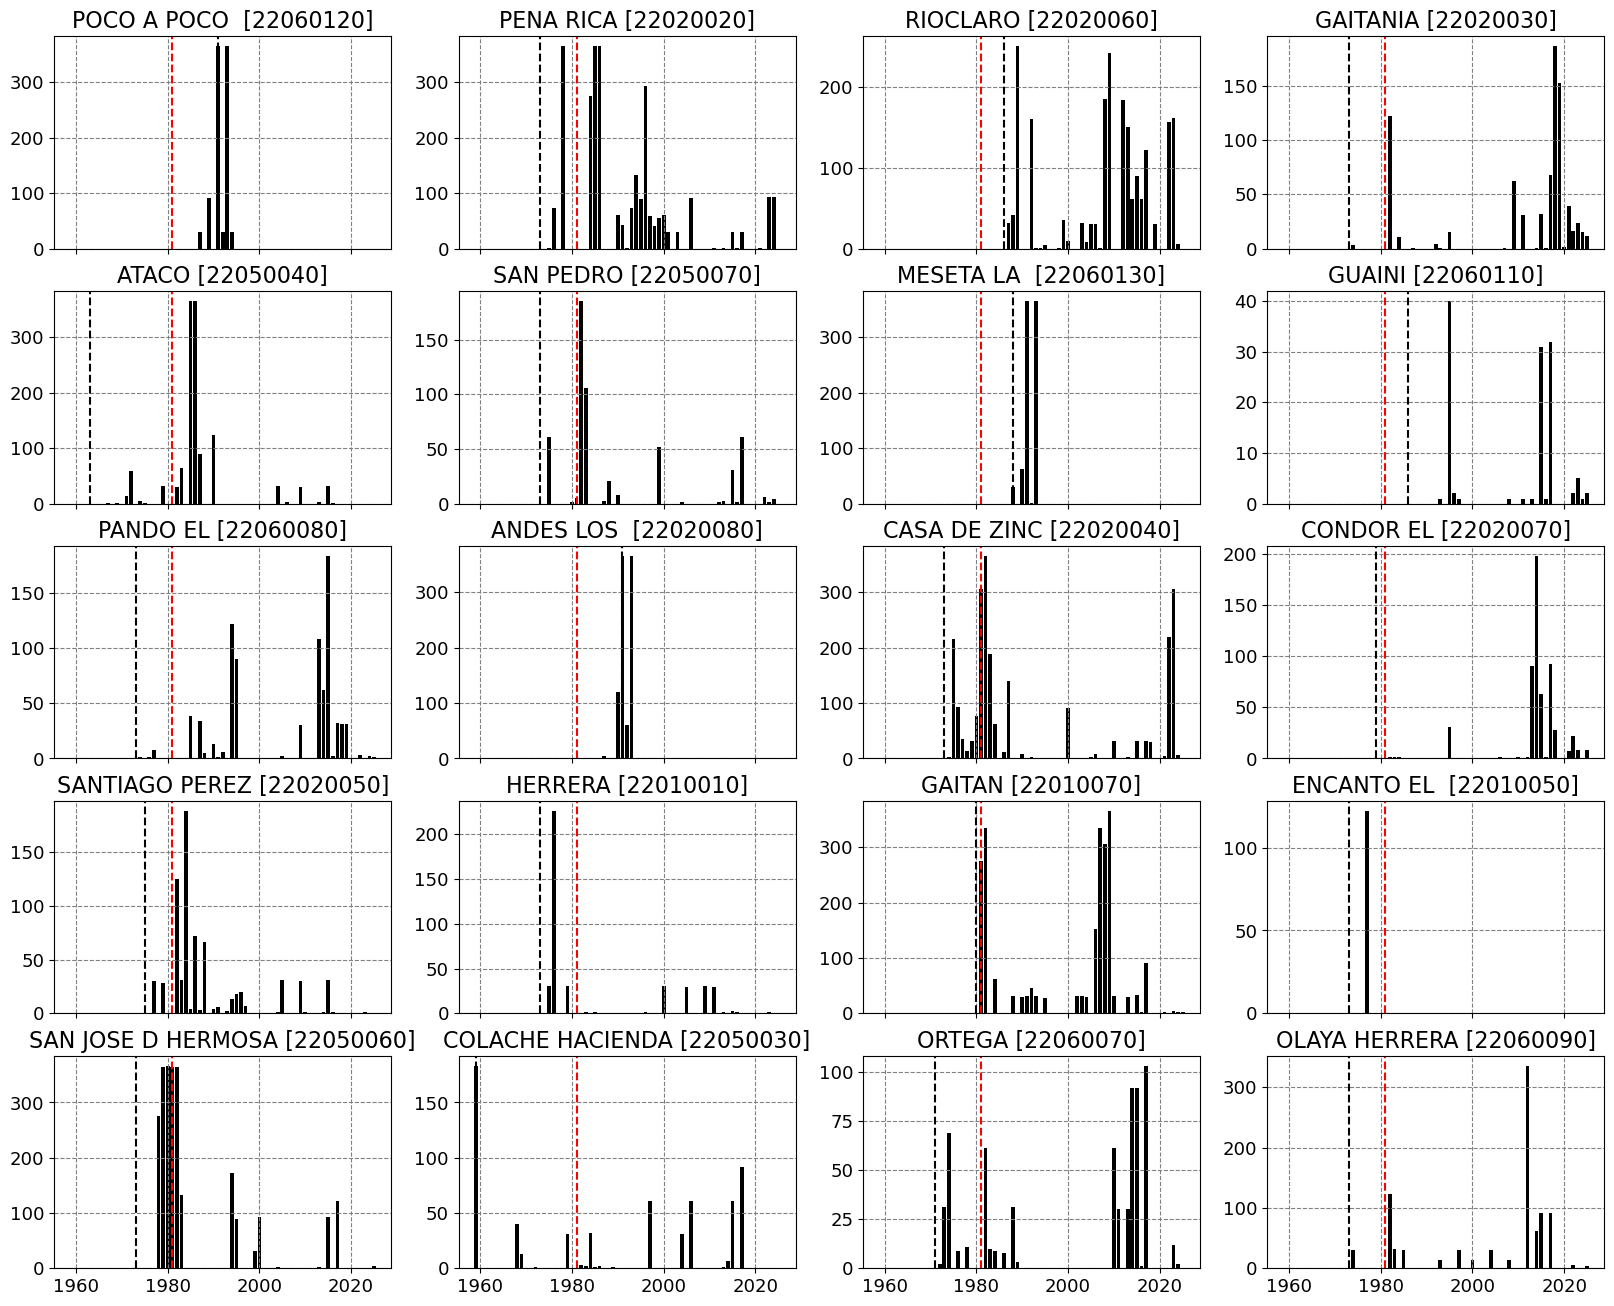

In [ ]:
from hidro_tools import funciones_hidrologicas
# Chequeo de la consistencia de la informacion
figs, axes = plt.subplots(5,4,figsize=(20,16),sharex=True)
axis = axes.flatten()
fecha_chirps = 1981
for idx,cod in enumerate(estaciones_pptn.index):

    path_file = estaciones_pptn.at[cod,'files_path']
    fecha_estacion = estaciones_pptn.at[cod,'Fecha_inst'].year
    nombre = estaciones_pptn.at[cod,'Nombre']

    # Lectura de datos
    df = funciones_hidrologicas.read_data(path_file)
    # faltantes
    df_faltantes = df.isna().groupby(df.index.year).sum()
    # ploteo
    x = df_faltantes.index
    y = df_faltantes.iloc[:,0]
    axis[idx].bar(x=x,height=y,color='black')
    axis[idx].set_title(nombre,fontsize=16)
    # axis[idx].ylabel('Faltantes',fontsize=16)
    axis[idx].tick_params(axis='both', labelsize=13)
    axis[idx].grid(linestyle='--',color='grey')
    # Lineas chirps
    axis[idx].axvline(
        x=fecha_chirps,
        color='r',
        linestyle="--",
        linewidth=1.5, 
        label="CHIRPS"
    )
    # Linea estacion
    axis[idx].axvline(
        x=fecha_estacion,
        color='black',
        linestyle="--",
        linewidth=1.5, 
        label="estacion"
    )

### Precipitación Chirps

In [4]:
das = []
for f in sorted(glob.glob('chirps_tifs/chirps_*.tif')):
    da = rioxarray.open_rasterio(f)
    year = int(re.search(r'chirps_(\d{4})\.tif', f).group(1))
    fechas = pd.date_range(f'{year}-01-01', periods=da.sizes['band'], freq='D')
    das.append(da.assign_coords(band=fechas).rename(band='time'))

pptn = xr.concat(das, dim='time')

ValueError: must supply at least one object to concatenate

In [3]:
# Cargar cuenca
path = 'cuenca_saldana'
cuenca_saldana = gpd.read_file(path)
# Cambiar crs
crs = pptn.rio.crs
cuenca_saldana = cuenca_saldana.to_crs(crs)

Cannot find header.dxf (GDAL_DATA is not defined)


In [4]:
path = 'dem_region_v2.tif'
dem = xr.open_dataset(path,engine='rasterio')
dem = dem.rename({"band_data": "elevation"})
dem = dem['elevation'][0, :, :]
dem = dem.where(dem != 0)
dem = dem.rio.write_crs('EPSG:32618')          # CRS original (solo etiqueta)
dem = dem.rio.write_nodata(float('nan'), encoded=False)
dem = dem.rio.reproject('EPSG:9377', resolution=30)

In [5]:
def clip_a_cuenca(da, gdf):
    g = gdf.to_crs(da.rio.crs)
    return da.rio.clip(g.geometry.values, crs=da.rio.crs, drop=True)

In [6]:
clip_pptn = clip_a_cuenca(pptn, cuenca_saldana)
clip_dem  = clip_a_cuenca(dem, cuenca_saldana)

### Modelo de Tanques

In [7]:
# Lectura de datos
df = pd.read_csv(
    'q_data/0022057010-Q_MEDIA_D.csv',
    index_col=0,
    parse_dates=True,
    usecols=[0,1]
)
df_pta_cobre = df.resample('D').mean()

In [51]:
t_inicial = '2005'
t_final = '2020'
t_final_pptn = str(int(t_final)-1)
mask = (df_pta_cobre.index >= t_inicial) & (df_pta_cobre.index < t_final)
q_pta_piedra = df_pta_cobre[mask]['valorObservado'].to_numpy()

In [52]:
# precipitacion
pptn_slice = clip_pptn.sel(time=slice(t_inicial,t_final_pptn))
pptn_cuenca = pptn_slice.mean(axis=1).mean(axis=1).to_numpy()

In [88]:
def params(cota:float,area:float,):
    
    params = [
    random.uniform(200,420), #Almacenamiento capilar (Tamaño del tanque)
    random.uniform(2, 90), # Conductividad de la capa superior
    random.uniform(6, 10) ,# Conducitividad capa inferior
    random.uniform(0,0.5), # Pérdidas subterráneas
    random.uniform(1.0,9), # Tiempo de residencia
    random.uniform(5.0,10.0), # Tiempo de residencia
    random.uniform(150,200),# Tiempo de residencia
    random.uniform(1,2),#alpha
    random.uniform(0.5,1),#beta
    random.uniform(1.0,1.15),# Param lluvia
    cota, #Altitud msnm
    area, #Area
    ]
    return params

In [89]:
#Almacenamiento simulaciones
simulaciones = list()
flujos_base = list()

#Diccionario almacenamiento resultados 
# y parametros
almacenamiento = {
    'almac_capilar':[],
    'ks':[],
    'kp':[],
    'perdidas_subt':[],
    'tr_2':[],
    'tr_3':[],
    'tr_4':[],
    'alpha':[],
    'beta':[],
    'Lluvia':[],
    'cond_iniciales':[],
    'Nash':[],
    'Nash_mod':[],
    'rmse':[],
    'rmse_mod':[],
    'Balance':[],
    'q_05':[],
}

#### Calibracion

In [90]:
# Parametros de Calibracion
date_cal = 10 * 365
# Caudal calibracion
q_cal = q_pta_piedra[:date_cal]
# Precipitacion de entrada
pptn_cal= pptn_cuenca[:date_cal]
# nombre_parametros
llaves = list(almacenamiento.keys())[:-7]
# Numero de iteraciones
max_iter = 1000

In [91]:
for iteracion in range(max_iter):
    # Estrucutra de corrida
    parametros = params(2134.65,7742.234)
    #Almacenamiento parametros
    #Parametros
    
    for idx,llave in enumerate(llaves):
        # Guarda los parametros utilizados
        almacenamiento[llave].append(parametros[idx])
    # Montaje de parametros al modelo
    modelo = modelo_tanques.modelo_tanques(pptn_cal,*parametros)
    # Simulacion
    caudal_sim, flujo_base = modelo.correr()
    simulaciones.append(caudal_sim)
    flujos_base.append(flujo_base)
    
    # Condiciones iniciales utilizadas
    cond_iniciales = modelo.cond_iniciales()
    # almacenamiento condiciones iniciales
    almacenamiento['cond_iniciales'].append(cond_iniciales)
    
    # Estimacion del error
    nash = funcion_objetivo.nash(q_cal,caudal_sim)
    nash_mod = funcion_objetivo.nash_sqrt(q_cal,caudal_sim)
    rmse = funcion_objetivo.rmse(q_cal,caudal_sim)
    rmse_mod = funcion_objetivo.rmse_modificado(q_cal,caudal_sim)
    balance = funcion_objetivo.balance(q_cal,caudal_sim)
    q_05 = funcion_objetivo.minimos(q_cal,caudal_sim)
    
    # Performance del modelo
    almacenamiento['Nash'].append(nash)
    almacenamiento['Nash_mod'].append(nash_mod)
    almacenamiento['rmse'].append(rmse)
    almacenamiento['rmse_mod'].append(rmse_mod)
    almacenamiento['Balance'].append(balance)
    almacenamiento['q_05'].append(q_05)
    
    
    if iteracion%1000 == 0:
        print(f'Iteracion:{iteracion}...')

Iteracion:0...


In [92]:
df_resultados = pd.DataFrame(almacenamiento)

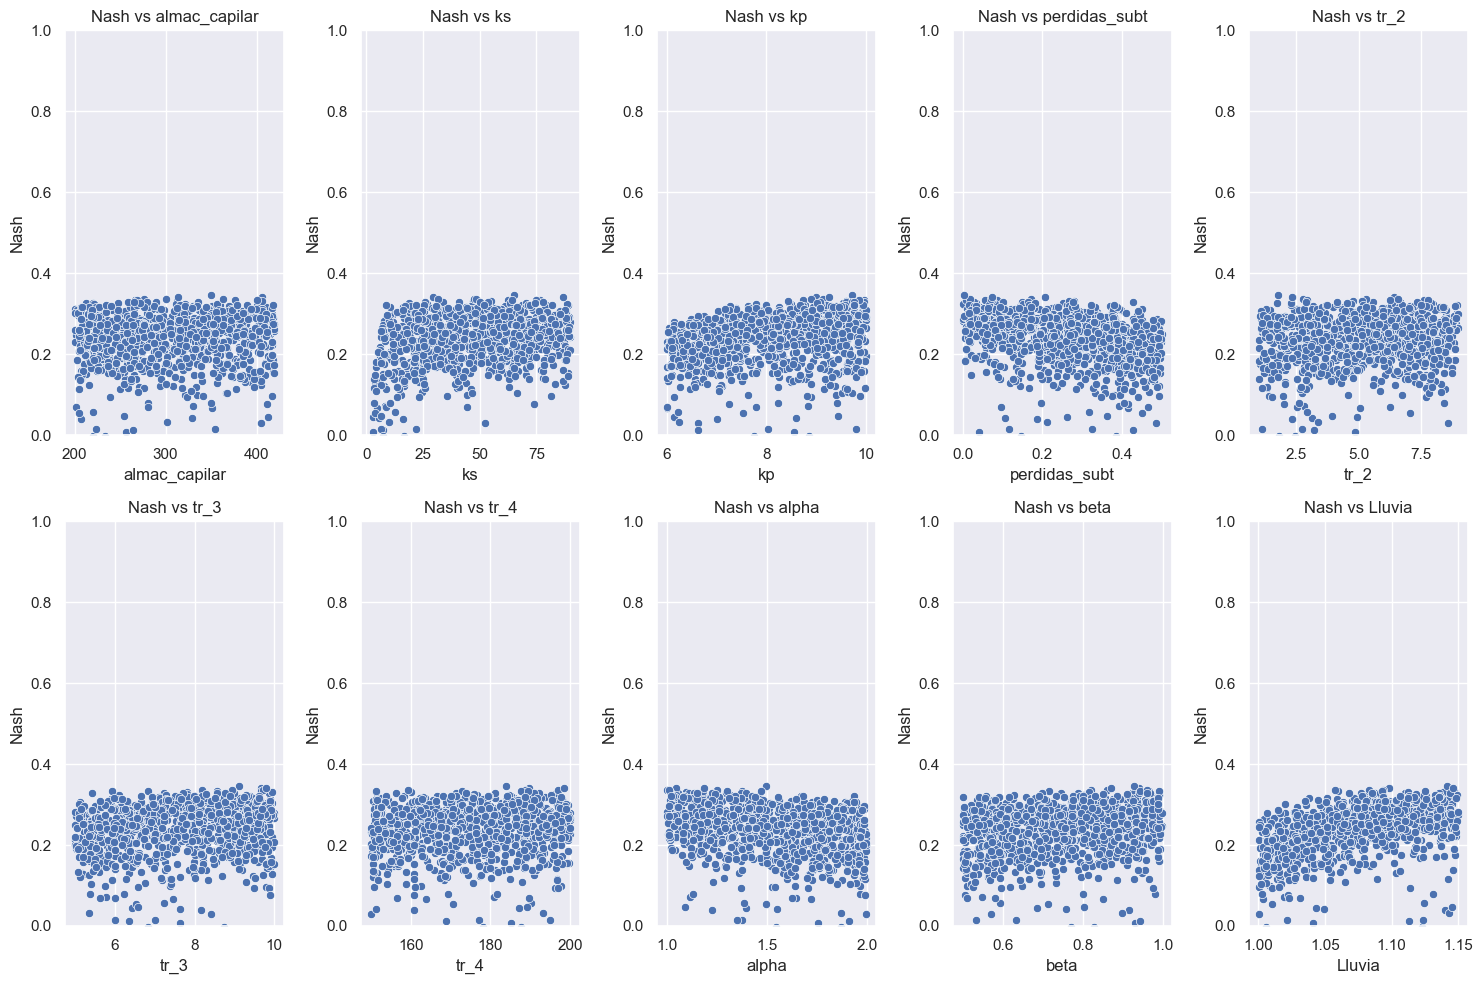

In [93]:
import seaborn as sns
fig, axes = plt.subplots(2, 5, figsize=(15, 10))  # Ajusta según el número de variables
axes = axes.flatten()

# Iterar sobre las columnas excepto 'Nash'
for i, col in enumerate(df_resultados.columns[:-7]):
    sns.scatterplot(data=df_resultados, x=col, y='Nash', ax=axes[i])
    axes[i].set_title(f'Nash vs {col}')
    axes[i].set_ylim(0,1)

# Ajuste de diseño
plt.tight_layout()
plt.show()

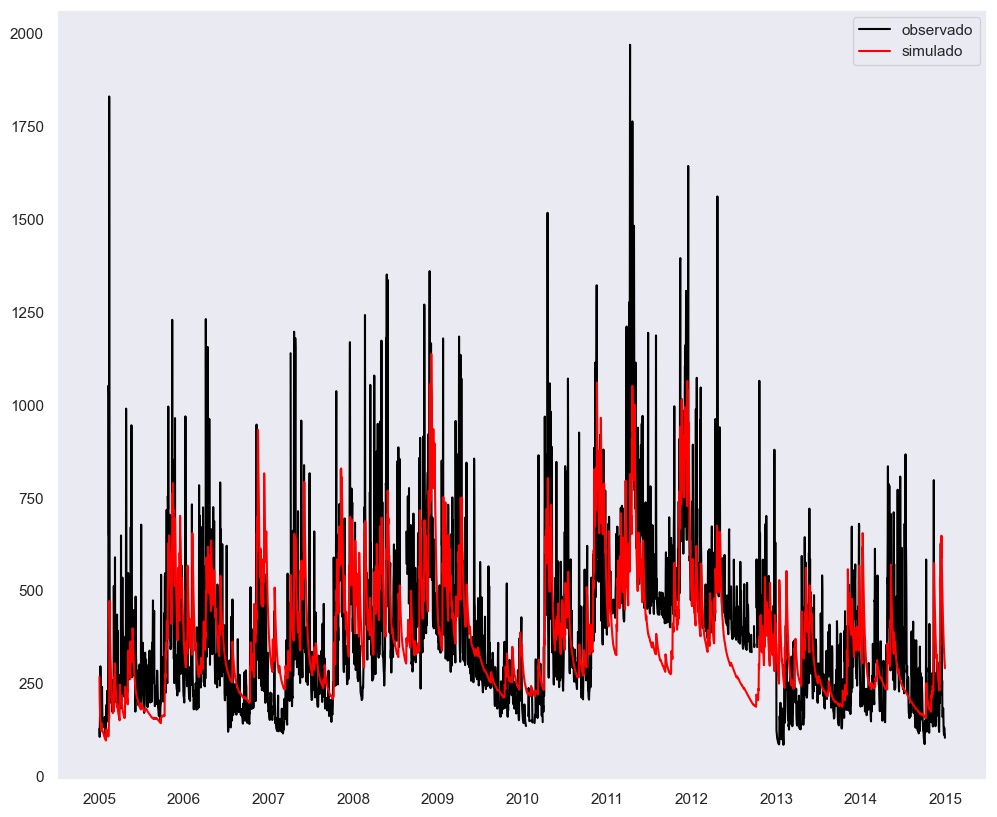

In [94]:
mask = df_resultados['Nash'] == df_resultados['Nash'].max()
mejor_ajuste = df_resultados[mask] 
id = mejor_ajuste.index[0]
t = pd.date_range(t_inicial,periods=10*365,freq='D')
plt.figure(figsize=(12,10))
plt.plot(t,q_cal,color='black',label='observado')
plt.plot(t,simulaciones[id],color='red',label='simulado')
plt.legend()
plt.grid()

In [100]:
mejor_ajuste

,almac_capilar,ks,kp,perdidas_subt,tr_2,tr_3,tr_4,alpha,beta,Lluvia,cond_iniciales,Nash,Nash_mod,rmse,rmse_mod,Balance,q_05
605,349.795359,65.27461,9.724187,0.003983,1.78011,9.123964,183.97093,1.493951,0.929009,1.141689,"[174.89767945566672, 1.7801096687021571, 9.123...",0.34571,0.35269,177.327,4.08,3.264169,19.372842


### Modelo GR4J

In [71]:
from hidro_tools import gr4j

In [72]:
def monte_carlo():
    # Se aplican los intervalos sugeridos en (Perrin, 2003)
    X1 = random.uniform(100, 1200) #100 - 1200
    X2 = random.uniform(-5, 3) #-5 - 3
    X3 = random.uniform(20, 300) #20 - 300
    X4 = random.uniform(1.1, 2.9) #1.1-2.9

    return X1,X2,X3,X4

def datos_iniciales():
    # Define las condiciones iniciales para el modelo
    x1 = random.uniform(0.6,0.8)
    x3 = random.uniform(0.6,0.8)

    return x1,x3

# Se ingresa el área de la cuenca
Area = 7742.234 #Km2
# Evapotranspiracion potencial
etp = 4.658*np.exp(-0.0002*(2134.65))
# Datos entrada para calibracion
etp_array_cal = np.ones_like(pptn_cal)*etp
# etp_array_cal = np.array(pet_data_entrada['Value'])
# q_obs = np.array(q_acotado['Valor'])[0:3649]
q_obs = q_cal.copy()
# Parametros Extraidos de la simulacion

#Ciclo for para generar simulaciones 

# Diccionario que almacena los resultados de las iteraciones

resultados = {

    'X1':[],
    'X2':[],
    'X3':[],
    'X4':[],
    'CI_X1':[],
    'CI_X3':[],
    'FO1':[],
    'FO2':[],
    'FO3':[],    
}

# Lista que almacena los caudales simulados

simulaciones = [

]

# Se inicia con 2000 simulaciones
for i in range(1000):
    params = monte_carlo()

    dic_params = {
        'X1':params[0],  # 100-1200
        'X2':params[1],  # -5 a 3
        'X3':params[2],  # 20-300
        'X4':params[3],  # 1.1-2.9
    }

    # Genera el porcentaje de inicio del production store y el routing store
    x1,x3 = datos_iniciales()

    # Condicione iniciales para ingreso al modelo
    cond_iniciales = {

            'production_store': x1 * params[0],
            'routing_store': x3 * params[2]
    }

    # Se almacenan las condiciones iniciales
    resultados['CI_X1'].append(x1)
    resultados['CI_X3'].append(x3)

    q_simulado = np.array(gr4j.gr4j(pptn_cal,
                                  etp_array_cal,
                                  dic_params,
                                  cond_iniciales))
    
    # La Salida del modelo se da en mm, por lo cual se multiplica por el área de la cuenca y se divide por el factor de escalamiento
    q_simulado_escalado = q_simulado*(Area)/86.4
    
    # Se almacenan las simulaciones
    simulaciones.append(q_simulado_escalado)
    
    # Almacenamiento de resultados
    resultados['X1'].append(params[0])      
    resultados['X2'].append(params[1])  
    resultados['X3'].append(params[2])  
    resultados['X4'].append(params[3])

    # Almacenamiento resultados del nash
    resultados['FO1'].append(funcion_objetivo.nash_sqrt(q_obs,q_simulado_escalado))
    resultados['FO2'].append(funcion_objetivo.nash_log(q_obs,q_simulado_escalado))
    resultados['FO3'].append(funcion_objetivo.nash(q_obs,q_simulado_escalado))

In [98]:
resultado_mc = pd.DataFrame.from_dict(resultados)
mask = resultado_mc['FO3'] == max(resultado_mc['FO3']) 
resultado_mc[mask]

,X1,X2,X3,X4,CI_X1,CI_X3,FO1,FO2,FO3
51,1104.141437,2.67429,145.126295,1.137424,0.746483,0.66355,0.1673,-0.13999,0.32828


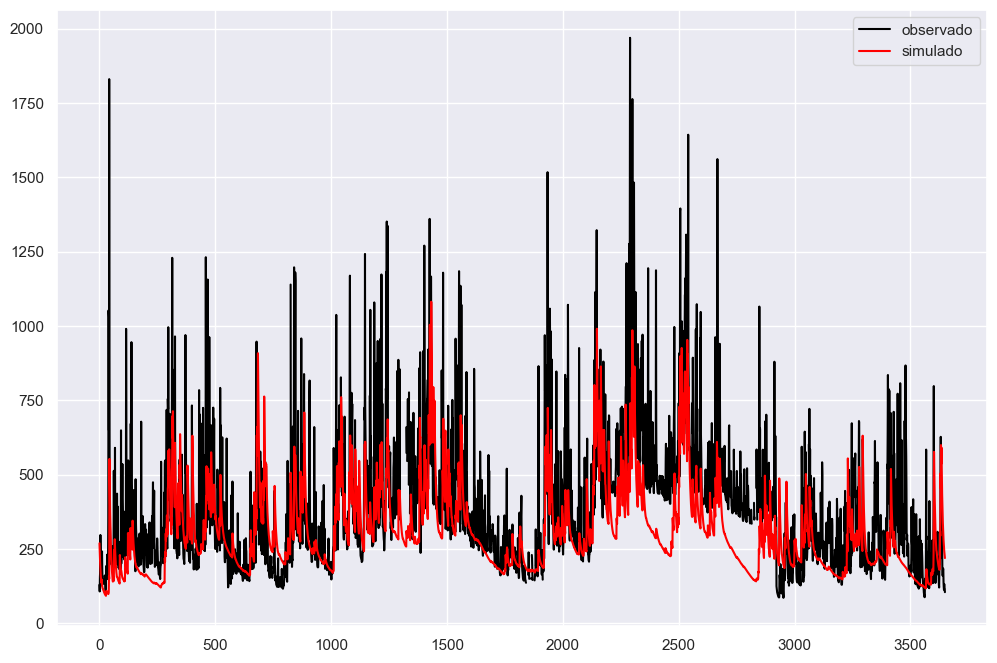

In [99]:
q_sim = simulaciones[51]
plt.figure(figsize=(12,8))
plt.plot(q_cal,color='black',label='observado')
plt.plot(q_sim,color='red',label='simulado')
plt.legend()

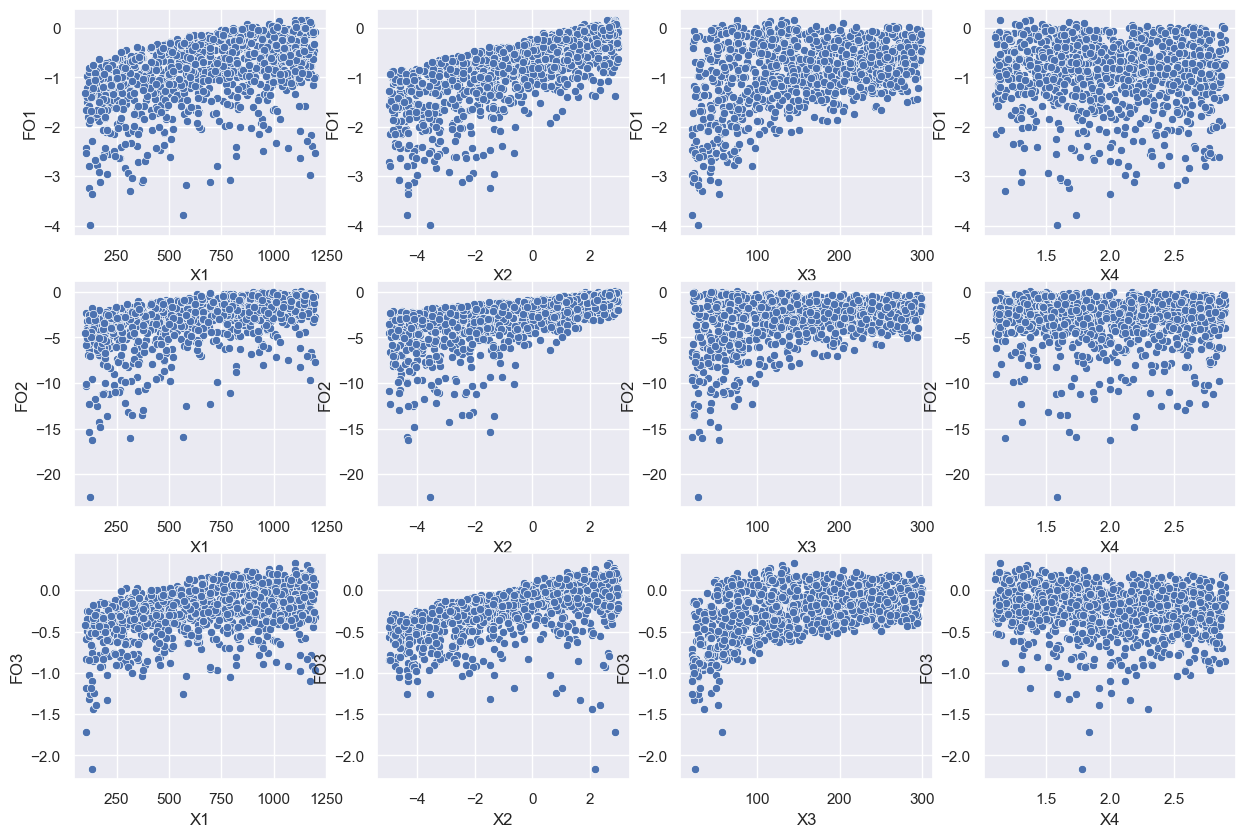

In [96]:

# Figuras de sensibilidad 
sns.set()
fig, axes = plt.subplots(
    3,4,
    figsize=(15,10),
    )


# Lista con 
params = list((resultado_mc.columns))[0:4]
fun_obj = list((resultado_mc.columns))[6:10]

for i in range(len(fun_obj)):
    for j in range(len(params)):

        # se crean los graficos
        sns.scatterplot(
            data=resultado_mc,
            x=params[j], 
            y=fun_obj[i],
            ax=axes[i,j]
        )

### Modelo machine learning
Para el modelo se planean utilizar serie de precipitación de toda la cuenca al igual que las estaciones de caudal aguas arriba de la estación Punta de Cobre 

#### Análisis de caudales

In [45]:
path = 'q_data'
files_estaciones = os.listdir(path)

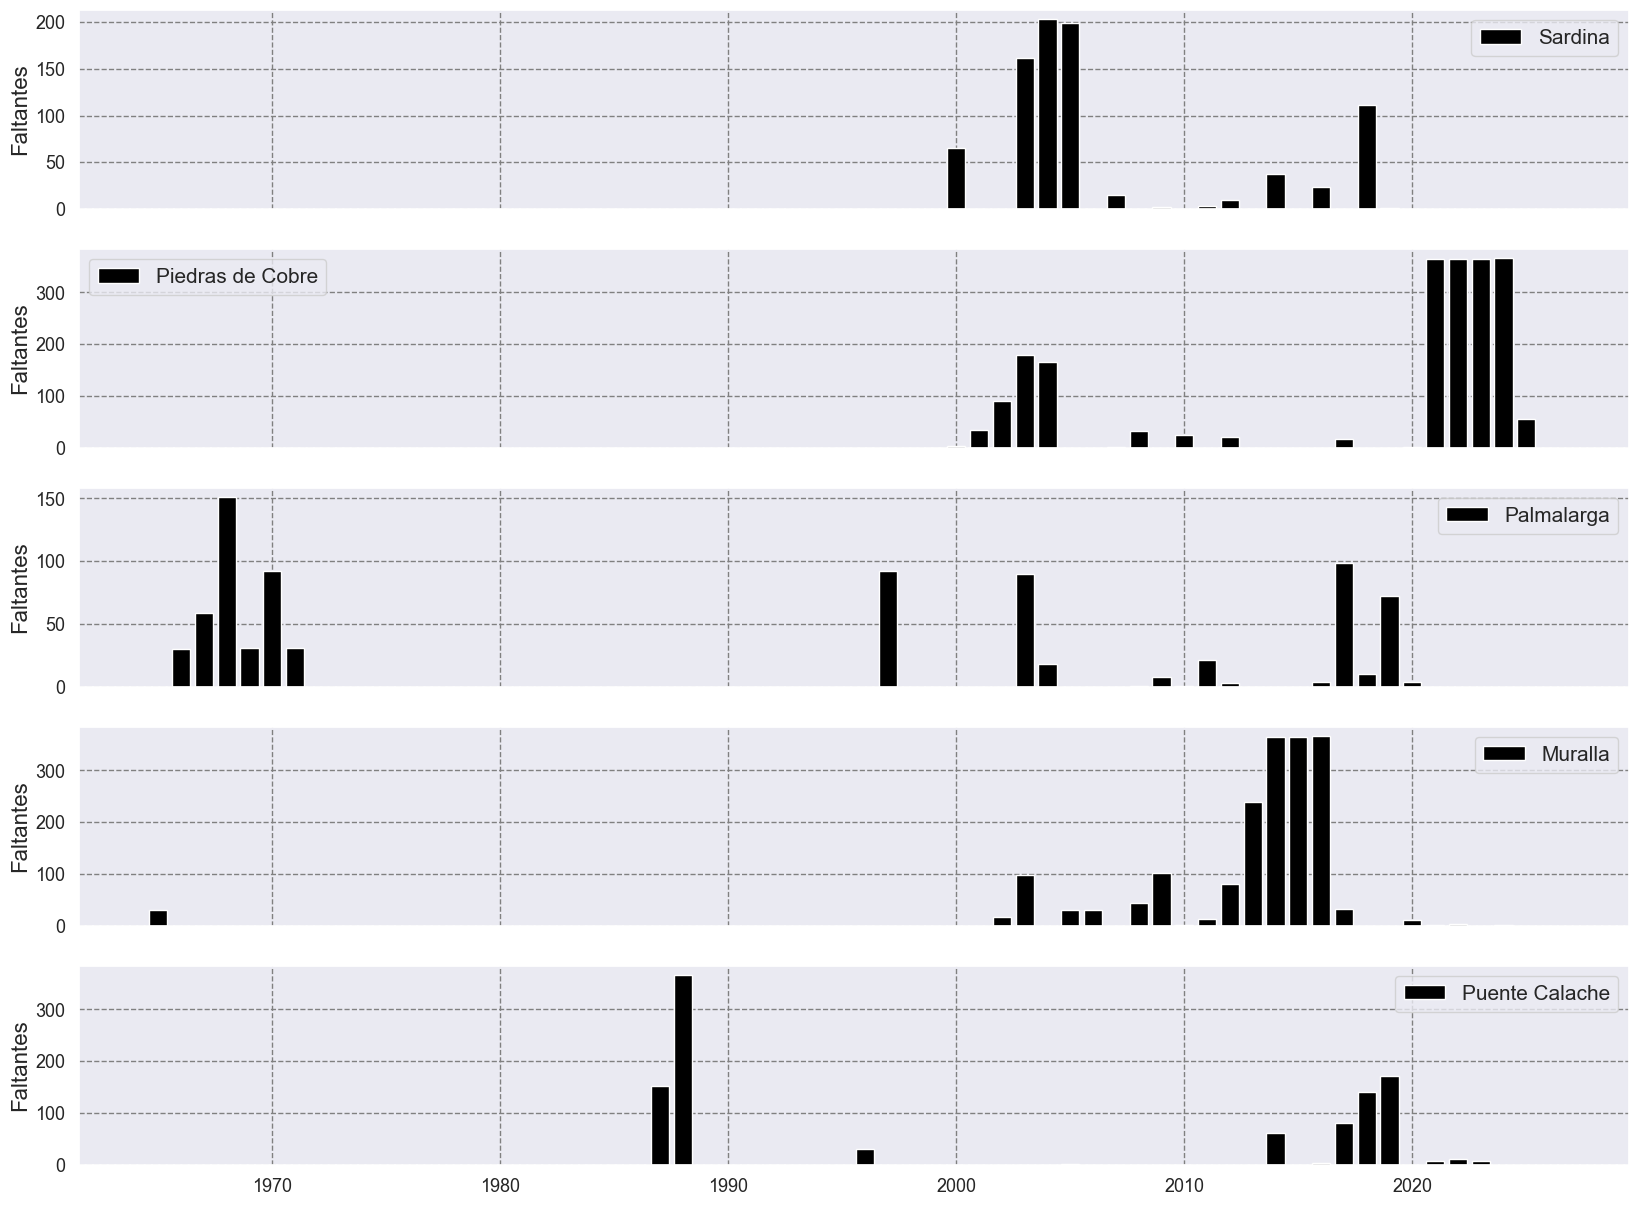

In [66]:
# Chequeo de datos faltantes
estaciones = {
    '0022017020':'Sardina',
    '0022057010':'Piedras de Cobre',
    '0022057040':'Palmalarga',
    '0022057060':'Muralla',
    '0022057070':'Puente Calache'
}
path_files = r'C:\Users\USUARIO\Documents\saldana_modelo\hidrologia_saldana\hidrologia_saldana\q_data'
# Chequeo de registro y datos faltantes
fig, axes = plt.subplots(5,1,figsize=(20,15),sharex=True)
axis = axes.flatten()
for idx,file in enumerate(files_estaciones):
    file_path = os.path.join(path_files,file)
    # Lectura de datos
    df = pd.read_csv(
        file_path,
        index_col=0,
        parse_dates=True,
        usecols=[0,1]
    )
    # Nombre de la estacion
    estacion_cod = file.split('-')[0]
    estacion_nombre = estaciones[estacion_cod]
    df = df.resample('D').mean()
    faltantes = df.isna().groupby(df.index.year).sum()
    # ploteo de los faltantes
    x = faltantes.index
    y = faltantes.iloc[:,0]
    axis[idx].bar(x=x,height=y,color='black',label=estacion_nombre)
    axis[idx].legend(fontsize=15)

    axis[idx].set_ylabel('Faltantes',fontsize=16)
    axis[idx].tick_params(axis='both', labelsize=13)
    axis[idx].grid(linestyle='--',color='grey')